In [1]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, applications
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)
from tensorflow.keras.optimizers import Adam

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

In [2]:
# ============================================================
# 2. CONFIGURATION — KAGGLE
# ============================================================

import os
import random
import numpy as np
import tensorflow as tf


# ============================================================
# SETTINGS
# ============================================================

SEED = 42

IMG_SIZE = (384, 384)
BATCH_SIZE = 32

# If GPU memory error:
# IMG_SIZE = (300, 300)
# BATCH_SIZE = 16

INITIAL_EPOCHS = 20
FINE_TUNE_EPOCHS = 20

NUM_CLASSES = 4


# ============================================================
# DATASET PATH
# ============================================================

# Your original Kaggle dataset was:
# /kaggle/input/ecg-image/ECG_DATA/

DATA_ROOT = "/kaggle/input/datasets/kanishkarathore1604/ecg-image/ECG_DATA"

TRAIN_DIR = os.path.join(
    DATA_ROOT,
    "train"
)

TEST_DIR = os.path.join(
    DATA_ROOT,
    "test"
)


# ============================================================
# CHECK DATASET
# ============================================================

print("=" * 60)
print("DATASET CHECK")
print("=" * 60)

print("Dataset root:", DATA_ROOT)
print("Train path  :", TRAIN_DIR)
print("Test path   :", TEST_DIR)

print("\nTrain exists:", os.path.exists(TRAIN_DIR))
print("Test exists :", os.path.exists(TEST_DIR))


# ============================================================
# STOP IF DATASET IS NOT FOUND
# ============================================================

if not os.path.exists(TRAIN_DIR):
    raise FileNotFoundError(
        f"Training folder not found:\n{TRAIN_DIR}\n\n"
        "Check the Kaggle dataset name and folder structure."
    )

if not os.path.exists(TEST_DIR):
    raise FileNotFoundError(
        f"Test folder not found:\n{TEST_DIR}\n\n"
        "Check the Kaggle dataset name and folder structure."
    )


# ============================================================
# FIND CLASSES
# ============================================================

train_classes = sorted([
    d
    for d in os.listdir(TRAIN_DIR)
    if os.path.isdir(
        os.path.join(TRAIN_DIR, d)
    )
])

test_classes = sorted([
    d
    for d in os.listdir(TEST_DIR)
    if os.path.isdir(
        os.path.join(TEST_DIR, d)
    )
])


print("\nTraining classes:")

for i, cls in enumerate(train_classes):
    print(f"{i}: {cls}")


print("\nTest classes:")

for i, cls in enumerate(test_classes):
    print(f"{i}: {cls}")


print("\nNumber of classes:", len(train_classes))


# ============================================================
# RANDOM SEED
# ============================================================

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


set_seed()

print("\nDataset ready!")

DATASET CHECK
Dataset root: /kaggle/input/datasets/kanishkarathore1604/ecg-image/ECG_DATA
Train path  : /kaggle/input/datasets/kanishkarathore1604/ecg-image/ECG_DATA/train
Test path   : /kaggle/input/datasets/kanishkarathore1604/ecg-image/ECG_DATA/test

Train exists: True
Test exists : True

Training classes:
0: ECG Images of Myocardial Infarction Patients (240x12=2880)
1: ECG Images of Patient that have History of MI (172x12=2064)
2: ECG Images of Patient that have abnormal heartbeat (233x12=2796)
3: Normal Person ECG Images (284x12=3408)

Test classes:
0: ECG Images of Myocardial Infarction Patients (240x12=2880)
1: ECG Images of Patient that have History of MI (172x12=2064)
2: ECG Images of Patient that have abnormal heartbeat (233x12=2796)
3: Normal Person ECG Images (284x12=3408)

Number of classes: 4

Dataset ready!


In [3]:
# ============================================================
# 4. DATA GENERATORS
# ============================================================
# IMPORTANT:
# Training gets augmentation.
# Validation and test DO NOT get random augmentation.

def adjust_contrast(image):
    image = tf.image.adjust_contrast(image, contrast_factor=1.3)
    return tf.clip_by_value(image, 0.0, 255.0)

train_datagen = ImageDataGenerator(
    rescale=1./255,
    preprocessing_function=adjust_contrast,
    rotation_range=2,
    width_shift_range=0.02,
    height_shift_range=0.02,
    zoom_range=0.03,
    brightness_range=[0.95, 1.05],
    fill_mode="constant",
    cval=0,
    validation_split=0.20
)

# Add preprocessing_function=adjust_contrast to BOTH val and test generators
val_datagen = ImageDataGenerator(
    rescale=1./255,
    preprocessing_function=adjust_contrast,
    validation_split=0.20
)

test_datagen = ImageDataGenerator(
    rescale=1./255,
    preprocessing_function=adjust_contrast
)


train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=SEED,
    color_mode="rgb"
)

val_generator = val_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=SEED,
    color_mode="rgb"
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
    color_mode="rgb"
)

class_names = list(train_generator.class_indices.keys())

print("\nClass indices:")
print(train_generator.class_indices)

print("\nImages:")
print("Training  :", train_generator.samples)
print("Validation:", val_generator.samples)
print("Test      :", test_generator.samples)
print("Classes   :", class_names)


Found 2420 images belonging to 4 classes.
Found 603 images belonging to 4 classes.
Found 928 images belonging to 4 classes.

Class indices:
{'ECG Images of Myocardial Infarction Patients (240x12=2880)': 0, 'ECG Images of Patient that have History of MI (172x12=2064)': 1, 'ECG Images of Patient that have abnormal heartbeat (233x12=2796)': 2, 'Normal Person ECG Images (284x12=3408)': 3}

Images:
Training  : 2420
Validation: 603
Test      : 928
Classes   : ['ECG Images of Myocardial Infarction Patients (240x12=2880)', 'ECG Images of Patient that have History of MI (172x12=2064)', 'ECG Images of Patient that have abnormal heartbeat (233x12=2796)', 'Normal Person ECG Images (284x12=3408)']


,Class,Training images
0,ECG Images of Myocardial Infarction Patients (...,765
1,ECG Images of Patient that have History of MI ...,413
2,ECG Images of Patient that have abnormal heart...,560
3,Normal Person ECG Images (284x12=3408),682


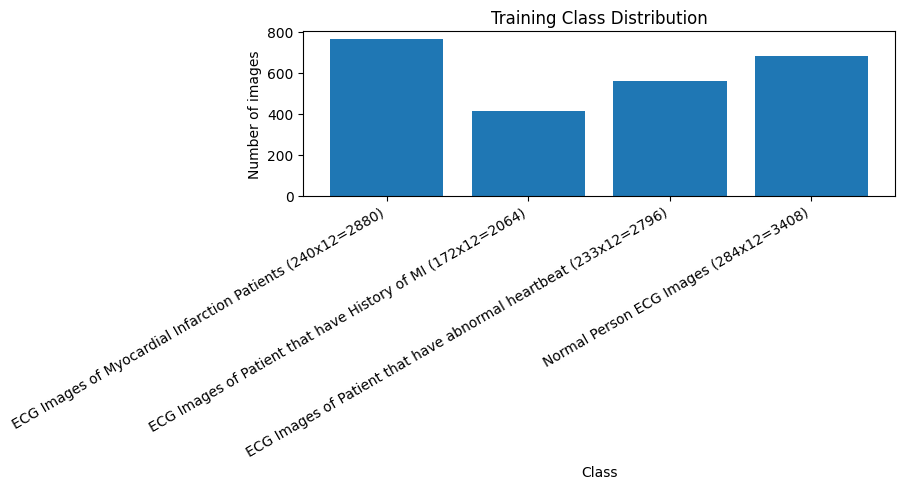

In [4]:
# ============================================================
# 5. CHECK CLASS DISTRIBUTION
# ============================================================
train_counts = np.bincount(train_generator.classes, minlength=NUM_CLASSES)

distribution = pd.DataFrame({
    "Class": class_names,
    "Training images": train_counts
})

display(distribution)

plt.figure(figsize=(9, 5))
plt.bar(class_names, train_counts)
plt.title("Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [5]:
# ============================================================
# 6. AUTOMATIC CLASS WEIGHTS
# ============================================================
classes = np.unique(train_generator.classes)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_generator.classes
)

class_weights = dict(zip(classes, weights))

print("Automatically calculated class weights:")
for idx, weight in class_weights.items():
    print(f"{idx} ({class_names[idx]}): {weight:.4f}")


Automatically calculated class weights:
0 (ECG Images of Myocardial Infarction Patients (240x12=2880)): 0.7908
1 (ECG Images of Patient that have History of MI (172x12=2064)): 1.4649
2 (ECG Images of Patient that have abnormal heartbeat (233x12=2796)): 1.0804
3 (Normal Person ECG Images (284x12=3408)): 0.8871


In [6]:
# ============================================================
# 7. BUILD DENSENET121 MODEL
# ============================================================
base_model = applications.DenseNet121(
    include_top=False,
    weights="imagenet",
    input_shape=(*IMG_SIZE, 3),
    pooling="avg"
)

# Stage 1: freeze pretrained feature extractor
base_model.trainable = False

inputs = layers.Input(shape=(*IMG_SIZE, 3))

x = base_model(inputs, training=False)
x = layers.Dense(256, activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.40)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classifier"
)(x)

model = models.Model(inputs, outputs, name="ECG_DenseNet121")

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "ECG_DenseNet121"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 1024)           │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,301,956 (27.85 MB)

 Trainable params: 263,940 (1.01 MB)

 Non-trainable params: 7,038,016 (26.85 MB)

In [7]:
# ============================================================
# 8. CALLBACKS
# ============================================================
SAVE_DIR = "/kaggle/working/ECG_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    SAVE_DIR,
    "best_ecg_densenet121.keras"
)

callbacks = [
    # Stop when validation loss stops improving
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    # Save the best model automatically
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    # Reduce learning rate if improvement stalls
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Best model will be saved at:", checkpoint_path)

Best model will be saved at: /kaggle/working/ECG_Models/best_ecg_densenet121.keras


In [8]:
# ============================================================
# 9. STAGE 1 — TRAIN CLASSIFICATION HEAD
# ============================================================
set_seed()

history_initial = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.3265 - loss: 1.7144 - precision: 0.3431 - recall: 0.2240
Epoch 1: val_loss improved from None to 1.21652, saving model to /kaggle/working/ECG_Models/best_ecg_densenet121.keras

Epoch 1: finished saving model to /kaggle/working/ECG_Models/best_ecg_densenet121.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 396s 5s/step - accuracy: 0.4182 - loss: 1.4357 - precision: 0.4548 - recall: 0.3033 - val_accuracy: 0.3781 - val_loss: 1.2165 - val_precision: 0.4557 - val_recall: 0.0597 - learning_rate: 1.0000e-04
Epoch 2/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5882 - loss: 1.0661 - precision: 0.6508 - recall: 0.4876
Epoch 2: val_loss improved from 1.21652 to 1.17005, saving model to /kaggle/working/ECG_Models/best_ecg_densenet121.keras

Epoch 2: finished saving model to /kaggle/working/ECG_Models/best_ecg_densenet121.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 224s 3s/step - accuracy: 0.5905 - loss: 1.0212 - precision: 0.6518 - recall: 0.4897 - va

In [9]:
# ============================================================
# 10. STAGE 2 — PARTIAL FINE-TUNING
# ============================================================
base_model.trainable = True

# Unfreeze only the last 30 layers for safer fine-tuning
FINE_TUNE_FROM = max(0, len(base_model.layers) - 30)

for layer in base_model.layers[:FINE_TUNE_FROM]:
    layer.trainable = False

# Keep BatchNorm frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_count = sum(
    int(layer.trainable) for layer in base_model.layers
)

print("Trainable DenseNet layers:", trainable_count)
print("Total DenseNet layers:", len(base_model.layers))

# Lower learning rate to 5e-6 to prevent destroying Stage 1 weights
model.compile(
    optimizer=Adam(learning_rate=5e-6),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

stage1_best_val_loss = min(history_initial.history["val_loss"])
print(f"Stage 1 best val_loss to beat: {stage1_best_val_loss:.4f}")

fine_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
         mode="min",
        initial_value_threshold=stage1_best_val_loss,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_fine = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=fine_callbacks,
    verbose=1
)

# Reload the best overall weights across BOTH Stage 1 and Stage 2
model.load_weights(checkpoint_path)
print("Loaded best overall weights from:", checkpoint_path)

Trainable DenseNet layers: 22
Total DenseNet layers: 428
Stage 1 best val_loss to beat: 1.0751
Epoch 1/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6686 - loss: 0.8447 - precision: 0.7221 - recall: 0.5828
Epoch 1: val_loss improved from 1.07510 to 0.99547, saving model to /kaggle/working/ECG_Models/best_ecg_densenet121.keras

Epoch 1: finished saving model to /kaggle/working/ECG_Models/best_ecg_densenet121.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 287s 3s/step - accuracy: 0.6831 - loss: 0.8052 - precision: 0.7343 - recall: 0.5983 - val_accuracy: 0.5755 - val_loss: 0.9955 - val_precision: 0.7018 - val_recall: 0.3864 - learning_rate: 5.0000e-06
Epoch 2/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6800 - loss: 0.8195 - precision: 0.7258 - recall: 0.5903
Epoch 2: val_loss did not improve from 0.99547
76/76 ━━━━━━━━━━━━━━━━━━━━ 232s 3s/step - accuracy: 0.6930 - loss: 0.7925 - precision: 0.7399 - recall: 0.6079 - val_accuracy: 0.5058 - val_loss: 1.0006 - val_precision: 0.5528 - va

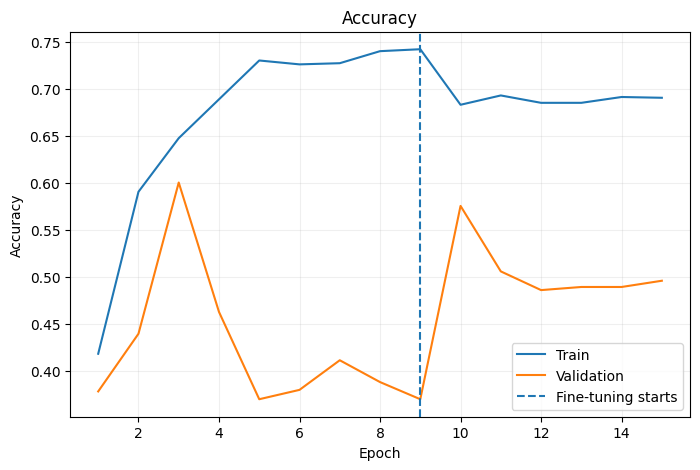

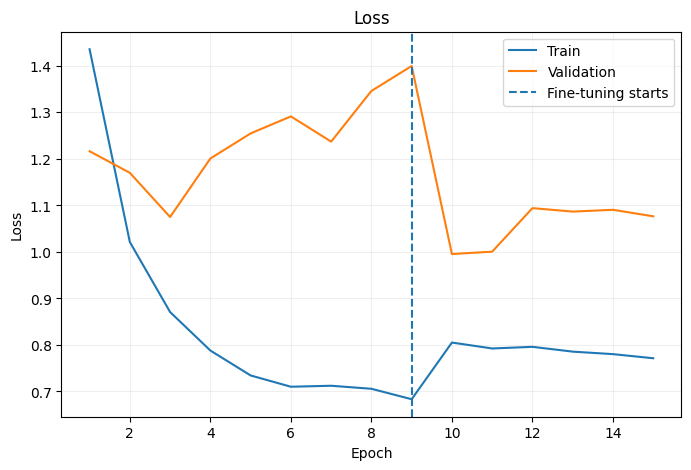

In [10]:
# ============================================================
# 11. TRAINING CURVES
# ============================================================
def combine_history(h1, h2):
    result = {}
    keys = set(h1.history.keys()).union(h2.history.keys())

    for key in keys:
        result[key] = (
            h1.history.get(key, []) +
            h2.history.get(key, [])
        )

    return result

history_all = combine_history(history_initial, history_fine)

epochs = range(1, len(history_all["loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history_all["accuracy"], label="Train")
plt.plot(epochs, history_all["val_accuracy"], label="Validation")
plt.axvline(
    len(history_initial.history["loss"]),
    linestyle="--",
    label="Fine-tuning starts"
)
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, history_all["loss"], label="Train")
plt.plot(epochs, history_all["val_loss"], label="Validation")
plt.axvline(
    len(history_initial.history["loss"]),
    linestyle="--",
    label="Fine-tuning starts"
)
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [11]:
# ============================================================
# 12. FINAL TEST PREDICTIONS
# ============================================================
# Always reset before prediction so the generator order is known.
test_generator.reset()

pred_probs = model.predict(
    test_generator,
    verbose=1
)

pred_classes = np.argmax(pred_probs, axis=1)
true_classes = test_generator.classes

print("Predictions:", pred_classes.shape)
print("Ground truth:", true_classes.shape)


29/29 ━━━━━━━━━━━━━━━━━━━━ 98s 3s/step
Predictions: (928,)
Ground truth: (928,)


In [12]:
# ============================================================
# 13. CLASSIFICATION REPORT
# ============================================================
print(
    classification_report(
        true_classes,
        pred_classes,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

accuracy = np.mean(pred_classes == true_classes)
precision = precision_score(
    true_classes, pred_classes,
    average="weighted", zero_division=0
)
recall = recall_score(
    true_classes, pred_classes,
    average="weighted", zero_division=0
)
f1 = f1_score(
    true_classes, pred_classes,
    average="weighted", zero_division=0
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")


                                                                  precision    recall  f1-score   support

      ECG Images of Myocardial Infarction Patients (240x12=2880)     1.0000    0.2678    0.4224       239
     ECG Images of Patient that have History of MI (172x12=2064)     0.3990    0.8837    0.5497       172
ECG Images of Patient that have abnormal heartbeat (233x12=2796)     0.8901    0.6953    0.7807       233
                          Normal Person ECG Images (284x12=3408)     0.6246    0.6620    0.6427       284

                                                        accuracy                         0.6099       928
                                                       macro avg     0.7284    0.6272    0.5989       928
                                                    weighted avg     0.7461    0.6099    0.6034       928

Accuracy : 0.6099
Precision: 0.7461
Recall   : 0.6099
F1-score : 0.6034


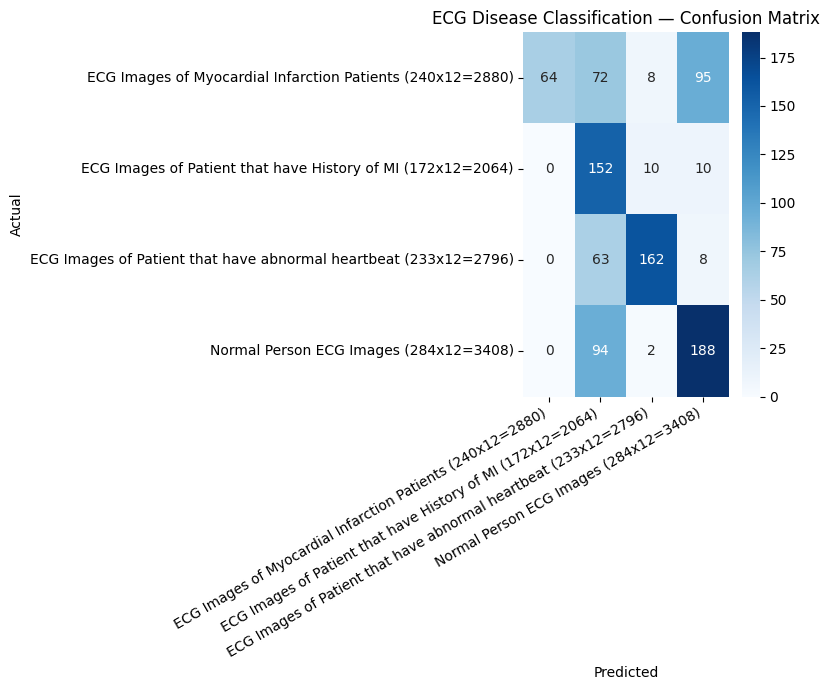

In [13]:
# ============================================================
# 14. CONFUSION MATRIX
# ============================================================
cm = confusion_matrix(
    true_classes,
    pred_classes,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(8, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ECG Disease Classification — Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [14]:
# ============================================================
# 15. PER-CLASS SENSITIVITY & SPECIFICITY
# ============================================================
metrics_rows = []

for i, class_name in enumerate(class_names):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - (tp + fn + fp)

    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0

    metrics_rows.append({
        "Class": class_name,
        "Sensitivity / Recall": sensitivity,
        "Specificity": specificity
    })

per_class_metrics = pd.DataFrame(metrics_rows)

display(
    per_class_metrics.style.format({
        "Sensitivity / Recall": "{:.4f}",
        "Specificity": "{:.4f}"
    })
)


,Class,Sensitivity / Recall,Specificity
0,ECG Images of Myocardial Infarction Patients (240x12=2880),0.2678,1.0000
1,ECG Images of Patient that have History of MI (172x12=2064),0.8837,0.6971
2,ECG Images of Patient that have abnormal heartbeat (233x12=2796),0.6953,0.9712
3,Normal Person ECG Images (284x12=3408),0.6620,0.8245


In [15]:
# ============================================================
# 16. MULTICLASS ROC-AUC
# ============================================================
try:
    y_true_onehot = tf.keras.utils.to_categorical(
        true_classes,
        num_classes=NUM_CLASSES
    )

    auc_score = roc_auc_score(
        y_true_onehot,
        pred_probs,
        multi_class="ovr",
        average="weighted"
    )

    print(f"Weighted One-vs-Rest ROC-AUC: {auc_score:.4f}")

except Exception as e:
    print("ROC-AUC could not be calculated:", e)


Weighted One-vs-Rest ROC-AUC: 0.9308


In [16]:
# ============================================================
# 17. SAVE MODEL
# ============================================================
SAVE_DIR = "/kaggle/working/ECG_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save complete model
final_model_path = os.path.join(
    SAVE_DIR,
    "ecg_densenet121.keras"
)

model.save(final_model_path)

# Save weights separately for Windows inference
weights_path = os.path.join(
    SAVE_DIR,
    "ecg_densenet121.weights.h5"
)

model.save_weights(weights_path)

print("Model saved to:")
print(final_model_path)

print("\nWeights saved to:")
print(weights_path)

Model saved to:
/kaggle/working/ECG_Models/ecg_densenet121.keras

Weights saved to:
/kaggle/working/ECG_Models/ecg_densenet121.weights.h5


In [17]:
import os
import json

TRAIN_DIR = "/kaggle/input/datasets/kanishkarathore1604/ecg-image/ECG_DATA/train"
SAVE_DIR = "/kaggle/working/ECG_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

# Get the class names from the training folders
class_names = sorted([
    folder for folder in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, folder))
])

print("Class names:", class_names)

# Save JSON
json_path = os.path.join(SAVE_DIR, "class_names.json")

with open(json_path, "w") as f:
    json.dump(class_names, f, indent=4)

print("JSON saved at:", json_path)

Class names: ['ECG Images of Myocardial Infarction Patients (240x12=2880)', 'ECG Images of Patient that have History of MI (172x12=2064)', 'ECG Images of Patient that have abnormal heartbeat (233x12=2796)', 'Normal Person ECG Images (284x12=3408)']
JSON saved at: /kaggle/working/ECG_Models/class_names.json


# 18. Grad-CAM Explainability

Grad-CAM highlights image regions that contribute most strongly to the selected prediction.

For ECG classification this is especially useful because it lets us inspect whether the network is focusing on waveform regions rather than irrelevant image artifacts.


In [18]:
# ============================================================
# 19. GRAD-CAM FUNCTIONS
# ============================================================
def find_last_conv_layer(model):
    # Search from the end for a convolutional layer.
    for layer in reversed(model.layers):
        if isinstance(layer, layers.Conv2D):
            return layer.name

    # DenseNet is nested inside the functional model.
    base = model.get_layer("densenet121")

    for layer in reversed(base.layers):
        if isinstance(layer, layers.Conv2D):
            return layer.name

    raise ValueError("No Conv2D layer found.")


def make_gradcam_heatmap(
    img_array,
    model,
    class_index=None
):
    # The nested DenseNet is the feature extractor.
    base_model = model.get_layer("densenet121")

    # DenseNet121's final convolutional feature map.
    last_conv_layer = None

    for layer in reversed(base_model.layers):
        if isinstance(layer, layers.Conv2D):
            last_conv_layer = layer
            break

    if last_conv_layer is None:
        raise ValueError("Could not find DenseNet convolution layer.")

    grad_model = tf.keras.models.Model(
        inputs=base_model.inputs,
        outputs=[
            last_conv_layer.output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, feature_output = grad_model(
            img_array,
            training=False
        )

        # Pass the feature vector through the classifier portion.
        x = model.layers[-3](feature_output)
        x = model.layers[-2](x)
        predictions = model.layers[-1](x)

        if class_index is None:
            class_index = tf.argmax(predictions[0])

        class_score = predictions[:, class_index]

    grads = tape.gradient(class_score, conv_outputs)

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), int(class_index)


In [21]:
# ============================================================
# 20. GRAD-CAM VISUALIZATION
# ============================================================
def show_gradcam(image_path, model, class_names):
    img = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    img_array = tf.keras.utils.img_to_array(img)
    img_array = img_array / 255.0
    batch = np.expand_dims(img_array, axis=0)

    probabilities = model.predict(batch, verbose=0)[0]
    predicted_class = int(np.argmax(probabilities))

    heatmap, _ = make_gradcam_heatmap(
        batch,
        model,
        class_index=predicted_class
    )

    heatmap = tf.image.resize(
        heatmap[..., np.newaxis],
        IMG_SIZE
    ).numpy().squeeze()

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img_array)
    plt.title("Original ECG")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap, cmap="jet")
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(img_array)
    plt.imshow(heatmap, cmap="jet", alpha=0.40)
    plt.title(
        f"{class_names[predicted_class]} "
        f"({probabilities[predicted_class] * 100:.2f}%)"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Prediction:", class_names[predicted_class])
    print("Confidence:", f"{probabilities[predicted_class] * 100:.2f}%")

    return probabilities


In [23]:
# ============================================================
# 17. SAVE ALL MODELS, JSON & CREATE DOWNLOADABLE ZIP
# ============================================================
import os
import json
import shutil
from IPython.display import FileLink, display

EXPORT_ROOT = "/kaggle/working/ECG_Export"
os.makedirs(EXPORT_ROOT, exist_ok=True)

# 1. Save complete Keras model (.keras)
keras_model_path = os.path.join(EXPORT_ROOT, "ecg_densenet121.keras")
model.save(keras_model_path)
print("Saved Keras model :", keras_model_path)

# 2. Save model weights (.weights.h5)
weights_path = os.path.join(EXPORT_ROOT, "ecg_densenet121.weights.h5")
model.save_weights(weights_path)
print("Saved weights     :", weights_path)

# 3. Export TensorFlow SavedModel folder (for tf.saved_model.load)
saved_model_dir = os.path.join(EXPORT_ROOT, "ecg_saved_model")
model.export(saved_model_dir)
print("Exported SavedModel:", saved_model_dir)

# 4. Save class_names.json
json_path = os.path.join(EXPORT_ROOT, "class_names.json")
with open(json_path, "w") as f:
    json.dump(class_names, f, indent=4)
print("Saved class names :", json_path)

# 5. Zip everything into a single file
zip_base_name = "/kaggle/working/ECG_Models_Bundle"
zip_file_path = shutil.make_archive(zip_base_name, "zip", EXPORT_ROOT)

print("\n" + "=" * 60)
print("ZIP CREATED SUCCESSFULLY:", zip_file_path)
print("=" * 60)

# Generate a clickable download link in Kaggle
display(FileLink("ECG_Models_Bundle.zip"))

Saved Keras model : /kaggle/working/ECG_Export/ecg_densenet121.keras
Saved weights     : /kaggle/working/ECG_Export/ecg_densenet121.weights.h5
INFO:tensorflow:Assets written to: /kaggle/working/ECG_Export/ecg_saved_model/assets


INFO:tensorflow:Assets written to: /kaggle/working/ECG_Export/ecg_saved_model/assets


Saved artifact at '/kaggle/working/ECG_Export/ecg_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 384, 384, 3), dtype=tf.float32, name='keras_tensor_428')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  137259242399952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137259242398224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137259242398416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137259242397840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137259242400144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137259242393040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137259242393232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137259242398032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137259242398608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137259242393808: TensorSpec(shape=(), dtype=tf.resourc

/kaggle/working/ECG_Models_Bundle.zip